<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/Jobsheet4%20PBL/Praktikum%203%20(JS4)%20PBL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Langkah 1: Persiapan dan Skala Data (Menggantikan make_blobs)

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, KMeans
from sklearn import metrics

# Membaca dataset cafes.csv dan reviews.csv
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')

# Agregasi data review per kafe
review_agg = df_reviews.groupby('cafe_id').agg({'rating': ['mean', 'count'], 'likes': 'sum'})
review_agg.columns = ['avg_review_rating', 'total_reviews_scraped', 'total_likes']
review_agg = review_agg.reset_index()

# Menggabungkan dataframe cafes dengan agregasi review
df = pd.merge(df_cafes, review_agg, on='cafe_id', how='left').fillna(0)

# Seleksi Fitur (Rating dan Review Count)
X = df[['rating', 'review_count']].values

# Normalisasi / scaling data agar jarak antar fitur seimbang
X_scaled = StandardScaler().fit_transform(X)

print("Bentuk data setelah scaling:", X_scaled.shape)

Bentuk data setelah scaling: (99, 2)


#Langkah 2: Visualisasi Data Awal

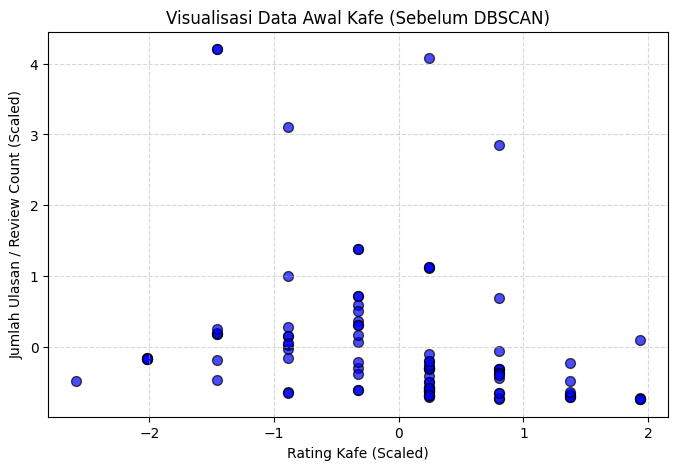

In [3]:
# Visualisasi data awal
plt.figure(figsize=(8, 5))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], s=50, color='blue', edgecolor='k', alpha=0.7)
plt.xlabel("Rating Kafe (Scaled)")
plt.ylabel("Jumlah Ulasan / Review Count (Scaled)")
plt.title("Visualisasi Data Awal Kafe (Sebelum DBSCAN)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

#Langkah 3: Menerapkan Algoritma DBSCAN

In [4]:
# Menerapkan DBSCAN
db = DBSCAN(eps=0.5, min_samples=5).fit(X_scaled)
labels = db.labels_

# Menghitung jumlah klaster (mengabaikan noise -1) dan jumlah titik noise
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print(f"Estimated number of clusters: {n_clusters_}")
print(f"Estimated number of noise points: {n_noise_}")

Estimated number of clusters: 7
Estimated number of noise points: 18


#Langkah 4: Evaluasi Kualitas Klasterisasi

In [5]:
# Membuat pseudo true labels menggunakan KMeans untuk perbandingan metrik eksternal
labels_true = KMeans(n_clusters=3, random_state=42).fit_predict(X_scaled)

# Evaluasi metrik klasterisasi
print(f"Homogeneity: {metrics.homogeneity_score(labels_true, labels):.3f}")
print(f"Completeness: {metrics.completeness_score(labels_true, labels):.3f}")
print(f"V-measure: {metrics.v_measure_score(labels_true, labels):.3f}")
print(f"Adjusted Rand Index: {metrics.adjusted_rand_score(labels_true, labels):.3f}")
print(f"Adjusted Mutual Information: {metrics.adjusted_mutual_info_score(labels_true, labels):.3f}")

if n_clusters_ > 1:
    print(f"Silhouette Coefficient: {metrics.silhouette_score(X_scaled, labels):.3f}")
else:
    print("Silhouette Coefficient tidak dapat dihitung karena klaster kurang dari 2.")

Homogeneity: 0.767
Completeness: 0.336
V-measure: 0.468
Adjusted Rand Index: 0.265
Adjusted Mutual Information: 0.437
Silhouette Coefficient: 0.403


#Langkah 5: Visualisasi Hasil Klasterisasi DBSCAN

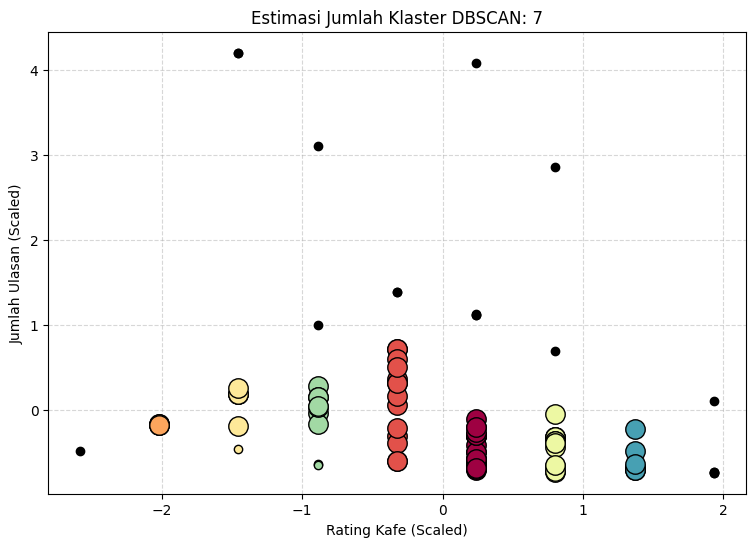

In [6]:
unique_labels = set(labels)
core_samples_mask = np.zeros_like(labels, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True

colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

plt.figure(figsize=(9, 6))
for k, col in zip(unique_labels, colors):
    if k == -1:
        # Warna hitam digunakan untuk noise / outlier
        col = [0, 0, 0, 1]

    class_member_mask = (labels == k)

    # Plot core samples (titik besar)
    xy = X_scaled[class_member_mask & core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=14,
    )

    # Plot non-core samples (titik kecil)
    xy = X_scaled[class_member_mask & ~core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=6,
    )

plt.title(f"Estimasi Jumlah Klaster DBSCAN: {n_clusters_}")
plt.xlabel("Rating Kafe (Scaled)")
plt.ylabel("Jumlah Ulasan (Scaled)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()